# Error analysis: DistilBERT vs Qwen

**Owner:** Tim McGowan (Group 4 is shared by the team)

The proposal asks: *do the two systems fail on the same pairs?* This notebook:

1. finds every **test** pair where DistilBERT (all 3,668 training pairs, seed 42) and Qwen (zero-shot) give **different** answers,
2. **auto-tags** each pair with a likely cause (changed numbers, negation, swapped roles, word overlap),
3. draws a **balanced sample of 50** of those pairs (25 where DistilBERT was right, 25 where Qwen was right) into a spreadsheet the team **checks by hand**,
4. summarizes the hand labels once they're filled in,
5. records the **majority-vote** check of all four models (the ensembling enhancement).

No model is loaded or trained: everything comes from the saved prediction files, so the whole notebook runs in seconds on any computer.

**The auto-tags are only a starting point.** They come from simple text rules, so the hand check is what counts for the report.

## 1. Find the project (clone it if we're in Colab)

In [1]:
# ━━━ CELL 1: FIND THE PROJECT (CLONE IT IF WE'RE IN COLAB) ━━━
import os
import sys
import time
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/freemanchamjames/nlp_paraphrase_detection.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    PROJECT_ROOT = Path("/content/nlp_paraphrase_detection")
    if PROJECT_ROOT.exists():
        r = subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--rebase"],
                           capture_output=True, text=True, timeout=120)
        if r.returncode != 0:
            print("git pull failed:", r.stderr.strip())
            backup = Path(f"/content/repo_backup_{int(time.time())}")
            PROJECT_ROOT.rename(backup)
            print("Moved old copy to", backup, "- cloning fresh")
    if not PROJECT_ROOT.exists():
        subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True, timeout=120)
else:
    PROJECT_ROOT = Path.cwd().resolve()
    while not (PROJECT_ROOT / "data" / "raw").exists():
        if PROJECT_ROOT == PROJECT_ROOT.parent:
            raise FileNotFoundError("Couldn't find the repo. Open this notebook from inside the project folder.")
        PROJECT_ROOT = PROJECT_ROOT.parent

print("Running in Colab:", IN_COLAB)
print("Project root:    ", PROJECT_ROOT)

Running in Colab: False
Project root:     D:\PycharmProjects\nlp_paraphrase_detection


## 2. Imports and shared settings

In [2]:
# ━━━ CELL 2: IMPORTS AND SHARED SETTINGS ━━━
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(PROJECT_ROOT))
from src.config import SEEDS, THRESHOLD, EXPECTED_COUNTS, evaluate

plt.style.use("default")        # white background, even under PyCharm's dark theme
pd.set_option("display.max_colwidth", 120)

## 3. Settings

- Which prediction files are compared. DistilBERT seed 42 is the same run used in the Findings doc.
- `SAMPLE_PER_SIDE = 25` means 25 pairs where only DistilBERT was right, plus 25 where only Qwen was right.
- `HAND_CATEGORIES` is the fixed list reviewers pick from, taken from the proposal.

In [3]:
# ━━━ CELL 3: SETTINGS ━━━
BERT_FILE = PROJECT_ROOT / "results" / "group3_distilbert" / "predictions" / "test_n3668_seed42.csv"
QWEN_FILE = PROJECT_ROOT / "results" / "group4_qwen" / "predictions" / "test_zeroshot.csv"

SAMPLE_PER_SIDE = 25
SAMPLE_SEED = SEEDS[0]          # 42, from src/config.py

HAND_CATEGORIES = [
    "high overlap, different meaning",
    "low overlap, same meaning",
    "negation",
    "swapped roles",
    "changed numbers or names",
    "extra or missing detail",
    "label looks wrong",
    "other",
]

OUT_DIR = PROJECT_ROOT / "results" / "error_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)
SHEET = OUT_DIR / "disagreements_50.csv"
print("Saving to:", OUT_DIR)

Saving to: D:\PycharmProjects\nlp_paraphrase_detection\results\error_analysis


## 4. Load the test pairs and both models' predictions

In [4]:
# ━━━ CELL 4: LOAD THE TEST PAIRS AND PREDICTIONS ━━━
test_df = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "test.csv")
assert (len(test_df), int(test_df.label.sum()), int((test_df.label == 0).sum())) == EXPECTED_COUNTS["test"]

bert = pd.read_csv(BERT_FILE).rename(columns={"prob_paraphrase": "bert_prob", "pred": "bert_pred"})
qwen = pd.read_csv(QWEN_FILE).rename(columns={"prob_paraphrase": "qwen_prob", "pred": "qwen_pred"})
df = (test_df.merge(bert[["idx", "bert_prob", "bert_pred"]], on="idx")
             .merge(qwen[["idx", "qwen_prob", "qwen_pred"]], on="idx"))
assert len(df) == len(test_df), "some test pairs are missing from a prediction file"

df["bert_right"] = df.bert_pred == df.label
df["qwen_right"] = df.qwen_pred == df.label

outcomes = pd.Series({
    "both right": (df.bert_right & df.qwen_right).sum(),
    "only DistilBERT right": (df.bert_right & ~df.qwen_right).sum(),
    "only Qwen right": (~df.bert_right & df.qwen_right).sum(),
    "both wrong": (~df.bert_right & ~df.qwen_right).sum(),
})
print("Test pairs:", len(df))
print(outcomes.to_string())
print(f"\nThey disagree on {(df.bert_pred != df.qwen_pred).sum()} pairs "
      f"({(df.bert_pred != df.qwen_pred).mean():.1%})")

Test pairs: 1725
both right               1170
only DistilBERT right     258
only Qwen right           137
both wrong                160

They disagree on 395 pairs (22.9%)


## 5. Auto-tag every pair

Simple text rules give each pair a few flags and one **auto category** (the first rule that applies, in this order):

| Flag | Rule |
|---|---|
| changed numbers | the two sentences contain different numbers |
| negation | "not", "no", "never" or "n't" appears in only one sentence |
| swapped roles | same words, different order |
| high overlap, different meaning | not a paraphrase, and at least 50% of words shared |
| low overlap, same meaning | a paraphrase, and under 40% of words shared |
| extra or missing detail | one sentence is at least 40% longer than the other |

Word overlap = shared distinct words ÷ all distinct words in the pair (Jaccard).

In [5]:
# ━━━ CELL 5: AUTO-TAG EVERY PAIR ━━━
def words(s):
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", s.lower())

def numbers(s):
    return set(re.findall(r"\d+(?:[.,]\d+)?", s))

NEG = re.compile(r"\b(not|no|never|none|nobody|nothing)\b|n't\b", re.I)

def tag(row):
    w1, w2 = words(row.sentence1), words(row.sentence2)
    s1, s2 = set(w1), set(w2)
    overlap = len(s1 & s2) / len(s1 | s2)
    longer, shorter = max(len(w1), len(w2)), max(1, min(len(w1), len(w2)))
    flags = {
        "word_overlap": round(overlap, 3),
        "changed_numbers": bool((numbers(row.sentence1) or numbers(row.sentence2))
                                and numbers(row.sentence1) != numbers(row.sentence2)),
        "negation": bool(NEG.search(row.sentence1)) != bool(NEG.search(row.sentence2)),
        "swapped_roles": sorted(w1) == sorted(w2) and w1 != w2,
        "extra_detail": longer / shorter >= 1.4,
    }
    if flags["changed_numbers"]:
        cat = "changed numbers or names"
    elif flags["negation"]:
        cat = "negation"
    elif flags["swapped_roles"]:
        cat = "swapped roles"
    elif row.label == 0 and overlap >= 0.5:
        cat = "high overlap, different meaning"
    elif row.label == 1 and overlap < 0.4:
        cat = "low overlap, same meaning"
    elif flags["extra_detail"]:
        cat = "extra or missing detail"
    else:
        cat = "other"
    flags["auto_category"] = cat
    return pd.Series(flags)

df = pd.concat([df, df.apply(tag, axis=1)], axis=1)
dis = df[df.bert_pred != df.qwen_pred].copy()
dis["who_right"] = np.where(dis.bert_right, "DistilBERT", "Qwen")
print("Auto categories among the", len(dis), "disagreements:")
print(dis.groupby(["auto_category", "who_right"]).size().unstack(fill_value=0).to_string())

Auto categories among the 395 disagreements:
who_right                        DistilBERT  Qwen
auto_category                                    
changed numbers or names                 85    50
extra or missing detail                  15    13
high overlap, different meaning          46    10
low overlap, same meaning                18    12
negation                                 12     8
other                                    82    44


## 6. How each model does by category (all 1,725 test pairs)

This uses **every** test pair, not just disagreements, so it shows each model's overall strengths and weak spots. The chart is saved with a white background for the report.

,pairs,paraphrase_share,distilbert_acc,qwen_acc
auto_category,,,,
other,885,0.821,0.903,0.860
changed numbers or names,442,0.471,0.771,0.692
"high overlap, different meaning",117,0.000,0.530,0.222
"low overlap, same meaning",117,1.000,0.821,0.769
extra or missing detail,97,0.546,0.804,0.784
negation,64,0.609,0.766,0.703
swapped roles,3,1.000,1.000,1.000


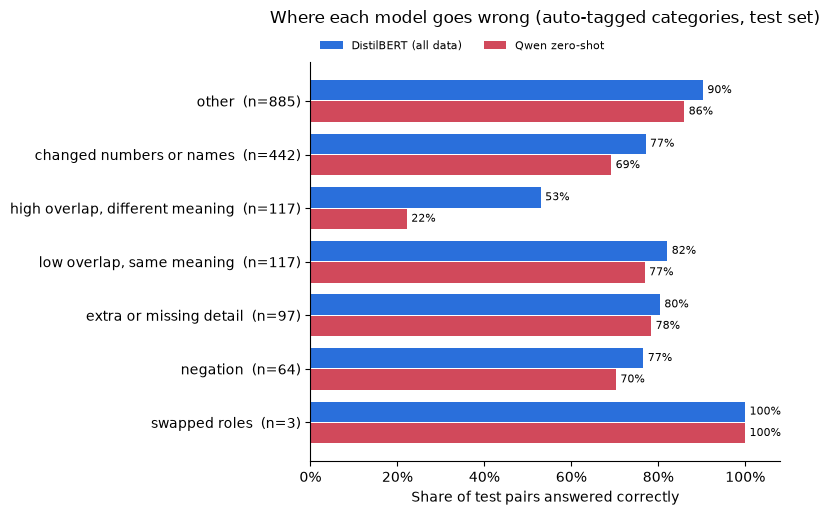

In [6]:
# ━━━ CELL 6: ACCURACY BY CATEGORY ━━━
by_cat = (df.groupby("auto_category")
            .agg(pairs=("idx", "count"), paraphrase_share=("label", "mean"),
                 distilbert_acc=("bert_right", "mean"), qwen_acc=("qwen_right", "mean"))
            .round(3).sort_values("pairs", ascending=False))
by_cat.to_csv(OUT_DIR / "accuracy_by_category.csv")
display(by_cat)

order = by_cat.index.tolist()
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 0.55 * len(order) + 1.4), facecolor="white")
ax.barh(y - 0.2, by_cat.distilbert_acc, height=0.38, color="#2a6fdb", label="DistilBERT (all data)")
ax.barh(y + 0.2, by_cat.qwen_acc, height=0.38, color="#d1495b", label="Qwen zero-shot")
for i, (b, q) in enumerate(zip(by_cat.distilbert_acc, by_cat.qwen_acc)):
    ax.text(b + 0.01, i - 0.2, f"{b:.0%}", va="center", fontsize=8)
    ax.text(q + 0.01, i + 0.2, f"{q:.0%}", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels([f"{c}  (n={n})" for c, n in zip(order, by_cat.pairs)])
ax.invert_yaxis()
ax.set_xlim(0, 1.08)
ax.set_xlabel("Share of test pairs answered correctly")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Where each model goes wrong (auto-tagged categories, test set)", pad=28)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "accuracy_by_category.png", dpi=150, facecolor="white")
plt.show()

## 7. Draw the 50 pairs for the hand check

**This cell never overwrites a sheet that has hand labels in it.** If `disagreements_50.csv` already exists, it's left alone. To redraw from scratch, delete the file first (only if nobody has started labeling).

**How the team fills it in:** open `results/error_analysis/disagreements_50.csv` in Excel or Google Sheets, and for each row fill in:
- `hand_category`: one of the `HAND_CATEGORIES` from Cell 3, typed exactly
- `notes`: a few words on *why* the wrong model was wrong
- `reviewer`: your name

Keep it as CSV when saving, then commit it.

In [7]:
# ━━━ CELL 7: DRAW THE 50 PAIRS FOR THE HAND CHECK ━━━
if SHEET.exists():
    sheet = pd.read_csv(SHEET)
    filled = sheet["hand_category"].notna().sum() if "hand_category" in sheet else 0
    print(f"{SHEET.name} already exists ({len(sheet)} rows, {filled} hand-labeled). Not overwriting.")
else:
    picks = []
    for side, mask in [("DistilBERT", dis.bert_right), ("Qwen", dis.qwen_right)]:
        pool = dis[mask]
        picks.append(pool.sample(min(SAMPLE_PER_SIDE, len(pool)), random_state=SAMPLE_SEED))
    sheet = (pd.concat(picks).sample(frac=1, random_state=SAMPLE_SEED)   # mix the two sides
               [["idx", "label", "who_right", "bert_prob", "qwen_prob", "word_overlap",
                 "auto_category", "changed_numbers", "negation", "swapped_roles", "extra_detail",
                 "sentence1", "sentence2"]]
               .reset_index(drop=True))
    sheet["bert_prob"] = sheet.bert_prob.round(3)
    sheet["qwen_prob"] = sheet.qwen_prob.round(3)
    sheet["hand_category"] = ""
    sheet["notes"] = ""
    sheet["reviewer"] = ""
    sheet.to_csv(SHEET, index=False)
    print(f"Wrote {SHEET} ({len(sheet)} rows)")

print(sheet.who_right.value_counts().to_string())
display(sheet[["idx", "label", "who_right", "auto_category", "sentence1", "sentence2"]].head(10))

Wrote D:\PycharmProjects\nlp_paraphrase_detection\results\error_analysis\disagreements_50.csv (50 rows)
who_right
DistilBERT    25
Qwen          25


,idx,label,who_right,auto_category,sentence1,sentence2
0,439,0,DistilBERT,other,"He refused to reveal what percentage of flights carried sky marshals , or whether they would be increased .",He refused to say what percentage of domestic flights had security officers on board .
1,335,0,Qwen,"high overlap, different meaning",But 13 people have been killed since 1900 and hundreds injured .,Runners are often injured by bulls and 13 have been killed since 1900 .
2,797,0,Qwen,changed numbers or names,"Shares of SCO closed at $ 10.93 , down 28 cents , in Monday trading on the Nasdaq Stock Market .","IBM shares closed up $ 1.75 , or 2.11 percent , at $ 84.50 on the New York Stock Exchange ."
3,1544,0,Qwen,negation,A subsequent report claimed that Jackson had actually become a member of the Nation of Islam .,Mr. Jackson is not Muslim nor a member of the Nation of Islam .
4,164,0,DistilBERT,"high overlap, different meaning","Amnesty International has said that over the past 20 years it has collected information about 17,000 disappearances ...","Amnesty International said that over the past 20 years it had collected information about 17,000 disappearances in I..."
5,385,0,Qwen,changed numbers or names,The initial report was made to Modesto Police December 28 .,It stems from a Modesto police report .
6,1222,1,Qwen,changed numbers or names,The supercomputer is actually an eServer and storage system with a peak speed of 7.3 trillion calculations per second .,It 's a cluster of 44 IBM servers with a peak speed of 7.3 trillion calculations per second .
7,1246,0,Qwen,other,Dell 's OpenManage software includes Dell Update Packages with SMS to help automate the management of server hardwar...,"The update packages help "" automate the management of server hardware , applications and operating systems patches u..."
8,1390,1,Qwen,changed numbers or names,"Once converted , BayStar will own an aggregate of approximately 2.95 million shares of SCO common stock or 17.5 perc...","The investment gives Larkspur , Calif.-based BayStar more than 2.9 million shares of SCO common stock , or 17.5 perc..."
9,356,0,DistilBERT,changed numbers or names,""" Whatever has happened to you by way of punishment is certainly more than enough , "" Covello told the 49-year-old ,...",""" What has happened to you , sir , by way of punishment , is certainly more than enough , "" Covello said ."


## 8. Summarize the hand labels (after the team fills in the sheet)

Until rows are labeled, this cell just says how many are left. Once they're done, it shows which kinds of pairs trip up each model, and how often the auto-tag agreed with the human.

In [8]:
# ━━━ CELL 8: SUMMARIZE THE HAND LABELS ━━━
sheet = pd.read_csv(SHEET)
labeled = sheet[sheet["hand_category"].fillna("").str.strip() != ""].copy()
print(f"Hand-labeled: {len(labeled)} of {len(sheet)}")

unknown = sorted(set(labeled.hand_category) - set(HAND_CATEGORIES))
if unknown:
    print("Check these labels, they aren't in HAND_CATEGORIES:", unknown)

if len(labeled):
    table = (labeled.groupby(["hand_category", "who_right"]).size()
                    .unstack(fill_value=0).reindex(columns=["DistilBERT", "Qwen"], fill_value=0))
    table.columns = ["only DistilBERT right", "only Qwen right"]
    table["total"] = table.sum(axis=1)
    table = table.sort_values("total", ascending=False)
    table.to_csv(OUT_DIR / "hand_label_summary.csv")
    display(table)
    agree = (labeled.hand_category == labeled.auto_category).mean()
    print(f"Auto-tag matched the hand label on {agree:.0%} of labeled rows")

Hand-labeled: 0 of 50


## 9. Majority vote of all four models (ensembling enhancement)

The proposal planned ensembling. A **majority vote** has nothing to train or tune, so it's fair to score directly on test. The version is **fixed in advance**: all four models (DistilBERT, Qwen zero-shot, logistic regression, feed-forward network), and "paraphrase" when at least 3 of 4 say so. A 2–2 tie goes to "not paraphrase".

Stacking (a trained combiner) was dropped by team vote; see the Findings doc for why.

In [9]:
# ━━━ CELL 9: MAJORITY VOTE OF ALL FOUR MODELS ━━━
members = {
    "DistilBERT": BERT_FILE,
    "Qwen zero-shot": QWEN_FILE,
    "Logistic regression": PROJECT_ROOT / "results" / "group2_logreg" / "test_seed42.csv",
    "Feed-forward network": PROJECT_ROOT / "results" / "group2_ffnn" / "test_seed42.csv",
}
votes = test_df[["idx", "label"]].copy()
rows = []
for name, path in members.items():
    p = pd.read_csv(path)[["idx", "pred"]].rename(columns={"pred": name})
    votes = votes.merge(p, on="idx")
    m = evaluate(votes.label, votes[name])
    rows.append({"model": name, "test_f1": round(m["f1"], 4), "test_accuracy": round(m["accuracy"], 4)})
assert len(votes) == len(test_df)

votes["majority"] = (votes[list(members)].sum(axis=1) >= 3).astype(int)
m = evaluate(votes.label, votes.majority)
rows.append({"model": "Majority vote (3 of 4)", "test_f1": round(m["f1"], 4), "test_accuracy": round(m["accuracy"], 4)})
vote_table = pd.DataFrame(rows)

ensemble_dir = PROJECT_ROOT / "results" / "ensemble"
ensemble_dir.mkdir(parents=True, exist_ok=True)
vote_table.to_csv(ensemble_dir / "majority_vote.csv", index=False)
display(vote_table)

err = pd.DataFrame({n: (votes[n] != votes.label).astype(int) for n in members})
print("How strongly the models' mistakes overlap (1 = always wrong together):")
display(err.corr().round(2))

,model,test_f1,test_accuracy
0,DistilBERT,0.8763,0.8278
1,Qwen zero-shot,0.8297,0.7577
2,Logistic regression,0.8164,0.7154
3,Feed-forward network,0.8149,0.7264
4,Majority vote (3 of 4),0.8544,0.7913


How strongly the models' mistakes overlap (1 = always wrong together):


,DistilBERT,Qwen zero-shot,Logistic regression,Feed-forward network
DistilBERT,1.00,0.32,0.36,0.33
Qwen zero-shot,0.32,1.00,0.42,0.37
Logistic regression,0.36,0.42,1.00,0.75
Feed-forward network,0.33,0.37,0.75,1.00


## 10. Save results to GitHub

Asks for your name and saves `last_run.json`. On a laptop, commit from PyCharm (tick `results/error_analysis`, `results/ensemble` and this notebook). In Colab it also asks for your GitHub email and pushes for you (classic token with `repo`, saved in Colab Secrets as `GITHUB_TOKEN`).

In [10]:
# ━━━ CELL 10: SAVE RESULTS TO GITHUB ━━━
import platform
from datetime import datetime

RUN_BY = ""
while not RUN_BY:
    RUN_BY = input("Your name (who ran this notebook): ").strip()
record = {"run_by": RUN_BY, "finished_at": datetime.now().isoformat(timespec="seconds"),
          "where": "Colab" if IN_COLAB else f"local ({platform.node()})"}
(OUT_DIR / "last_run.json").write_text(json.dumps(record, indent=2))
print(json.dumps(record, indent=2))

if IN_COLAB:
    RUN_EMAIL = ""
    while "@" not in RUN_EMAIL:
        RUN_EMAIL = input("Your GitHub email: ").strip()
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    push_url = REPO_URL.replace("https://", f"https://x-access-token:{token}@")

    def git(*cmd):
        r = subprocess.run(["git", "-C", str(PROJECT_ROOT), *cmd], capture_output=True, text=True)
        print((r.stdout + r.stderr).replace(token, "***").strip())
        return r.returncode

    git("config", "user.name", RUN_BY)
    git("config", "user.email", RUN_EMAIL)
    git("add", "results/error_analysis", "results/ensemble")
    git("commit", "-m", f"Error analysis results, run by {RUN_BY}")
    git("pull", "--rebase", push_url, "main")
    if git("push", push_url, "HEAD:main") == 0:
        print("Pushed to GitHub.")
else:
    print("\nLocal run: commit from PyCharm (results/error_analysis, results/ensemble, this notebook).")

{
  "run_by": "Tim McGowan",
  "finished_at": "2026-11-04T13:25:06",
  "where": "local (Draconis)"
}

Local run: commit from PyCharm (results/error_analysis, results/ensemble, this notebook).
